In [2]:
import glob
import os
from PIL import Image

# 1. 创建保存切片的文件夹
save_img_dir = '/kaggle/working/inria_patches/images'
save_gt_dir = '/kaggle/working/inria_patches/gt'
os.makedirs(save_img_dir, exist_ok=True)
os.makedirs(save_gt_dir, exist_ok=True)

# 2. 匹配数据集中的图片
input_root = '/kaggle/input'
img_files = sorted(
    glob.glob(
        os.path.join(input_root, '**/train/images/*.tif'), recursive=True
    )
)
gt_files = sorted(
    glob.glob(os.path.join(input_root, '**/train/gt/*.tif'), recursive=True)
)

# ⚡ 精简提速：只取前 25 张大图进行切片，控制在 30 秒内完成
img_files = img_files[:25]

print(f'🔍 正在对前 {len(img_files)} 张大图进行极速切片 (512x512)...')

patch_size = 512
count = 0

for i, img_path in enumerate(img_files):
  base_name = os.path.basename(img_path).replace('.tif', '')
  gt_path_candidates = [g for g in gt_files if base_name in g]
  if not gt_path_candidates:
    continue
  gt_path = gt_path_candidates[0]

  img = Image.open(img_path)
  gt = Image.open(gt_path)

  w, h = img.size
  for x in range(0, w, patch_size):
    for y in range(0, h, patch_size):
      if x + patch_size <= w and y + patch_size <= h:
        box = (x, y, x + patch_size, y + patch_size)
        patch_img = img.crop(box)
        patch_gt = gt.crop(box)

        patch_name = f'{base_name}_{x}_{y}.png'
        patch_img.save(os.path.join(save_img_dir, patch_name))
        patch_gt.save(os.path.join(save_gt_dir, patch_name))
        count += 1

print(
    f'✅ 切片准备完成！共生成 {count} 张高质量训练小图（耗时约 30 秒）。'
)

🔍 正在对前 25 张大图进行极速切片 (512x512)...
✅ 切片准备完成！共生成 2025 张高质量训练小图（耗时约 30 秒）。


In [ ]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset, random_split
from torch.optim.lr_scheduler import CosineAnnealingLR

# ==========================================
# 1. 设备检查与目录配置
# ==========================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"⚡ 当前运行设备: {DEVICE}")

img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

# ==========================================
# 2. 数据集定义 (包含动态边缘提取)
# ==========================================
class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        
        image_tensor = torchvision.transforms.ToTensor()(image)
        label_np = (np.array(label) > 127).astype(np.int64)
        label_tensor = torch.tensor(label_np, dtype=torch.long)
        
        # 动态抽取建筑物轮廓 (Edge)
        label_float = label_tensor.unsqueeze(0).float()
        dilated = F.max_pool2d(
            label_float.unsqueeze(0), kernel_size=3, stride=1, padding=1
        ).squeeze(0)
        edge_tensor = (dilated - label_float).squeeze(0)
        
        return image_tensor, label_tensor, edge_tensor

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=0)


# ==========================================
# 3. 网络模型结构定义
# ==========================================
class EdgeBranch(nn.Module):
    def __init__(self, in_channels, out_channels=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
        self.edge_head = nn.Conv2d(out_channels, 1, kernel_size=1)

    def forward(self, x):
        feat = self.conv(x)
        edge_out = self.edge_head(feat)
        return feat, edge_out

class ResNetSemanticBranch(nn.Module):
    def __init__(self, out_channels=64):
        super().__init__()
        resnet = models.resnet18(weights=None)
        self.backbone = nn.Sequential(
            resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool,
            resnet.layer1, resnet.layer2, resnet.layer3, resnet.layer4
        )
        self.smooth = nn.Sequential(
            nn.Conv2d(512, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        return F.interpolate(
            self.smooth(self.backbone(x)), size=(h, w), mode='bilinear', align_corners=False
        )

class EdgeEnhancedNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=2, use_edge=True):
        super().__init__()
        self.use_edge = use_edge
        self.semantic_branch = ResNetSemanticBranch(out_channels=64)
        fusion_in = 64 + 32 if self.use_edge else 64
        self.fusion = nn.Sequential(
            nn.Conv2d(fusion_in, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, num_classes, kernel_size=1)
        )
        if self.use_edge:
            self.edge_branch = EdgeBranch(in_channels, out_channels=32)

    def forward(self, x):
        semantic_feat = self.semantic_branch(x)
        if self.use_edge:
            edge_feat, _ = self.edge_branch(x)
            if semantic_feat.shape[2:] != edge_feat.shape[2:]:
                semantic_feat = F.interpolate(
                    semantic_feat, size=edge_feat.shape[2:], mode='bilinear', align_corners=False
                )
            fused_feat = torch.cat([semantic_feat, edge_feat], dim=1)
        else:
            fused_feat = semantic_feat
        return self.fusion(fused_feat)

# 🌟 实例化模型 (解决 name 'model' is not defined 的关键步骤)
model = EdgeEnhancedNet(in_channels=3, num_classes=2, use_edge=True).to(DEVICE)


# ==========================================
# 4. 边缘增强损失函数定义
# ==========================================
ce_loss = nn.CrossEntropyLoss()

def dice_loss(outputs, labels, smooth=1e-5):
    preds = torch.softmax(outputs, dim=1)[:, 1] 
    labels_float = (labels == 1).float()
    intersection = (preds * labels_float).sum(dim=(1, 2))
    union = preds.sum(dim=(1, 2)) + labels_float.sum(dim=(1, 2))
    return (1 - (2. * intersection + smooth) / (union + smooth)).mean()

def combined_loss(outputs, labels, edges):
    loss_ce = ce_loss(outputs, labels)
    loss_dice = dice_loss(outputs, labels)
    
    pixel_wise_ce = nn.CrossEntropyLoss(reduction='none')(outputs, labels)
    if edges.dim() == 4:
        edges = edges.squeeze(1)
        
    edge_penalty_weight = 2.0 
    loss_edge_penalty = (pixel_wise_ce * edges).mean() * edge_penalty_weight
    
    return loss_ce + loss_dice + loss_edge_penalty


# ==========================================
# 5. 优化器、调度器与模型保存配置
# ==========================================
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
NUM_EPOCHS = 15
scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-5)
scaler = torch.amp.GradScaler('cuda')

best_iou = 0.0
save_path = '/kaggle/working/best_inria_model.pth'


# ==========================================
# 6. 主训练 + 验证集评估 + 自动保存模型
# ==========================================
print('\n------------------- 开始训练 (15 Epochs, 带边缘增强) -------------------')

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{NUM_EPOCHS}]")
    
    for images, labels, edges in pbar:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        edges = edges.to(DEVICE, non_blocking=True)
        
        optimizer.zero_grad()
        
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = combined_loss(outputs, labels, edges)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        train_loss += loss.item()
        pbar.set_postfix({'loss': f"{loss.item():.4f}"})
        
    scheduler.step()
    
    # 每个 Epoch 结束，在验证集上计算 IoU 并保存最高分的模型权重
    model.eval()
    total_intersection = 0
    total_union = 0
    with torch.no_grad():
        for images, labels, _ in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            
            intersection = ((preds == 1) & (labels == 1)).sum().item()
            union = ((preds == 1) | (labels == 1)).sum().item()
            total_intersection += intersection
            total_union += union
            
    val_iou = total_intersection / (total_union + 1e-6)
    print(f"👉 Epoch {epoch+1} 结束 | 平均训练 Loss: {train_loss/len(train_loader):.4f} | 验证集 IoU: {val_iou:.4f}")
    
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), save_path)
        print(f"  🏆 刷新最高分 IoU ({val_iou:.4f})，已成功保存最佳模型至: {save_path}")

print(f"\n🎉 训练全部完成！最佳权重已稳定保存在：{save_path}")

In [ ]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as T
from PIL import Image
from torch.utils.data import DataLoader, Dataset, random_split
from tqdm import tqdm

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# ==========================================
# 1. 完全一致的模型结构定义
# ==========================================
class EdgeBranch(nn.Module):

  def __init__(self, in_channels, out_channels=32):
    super().__init__()
    self.conv = nn.Sequential(
        nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
        nn.Conv2d(32, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )
    self.edge_head = nn.Conv2d(out_channels, 1, kernel_size=1)

  def forward(self, x):
    feat = self.conv(x)
    edge_out = self.edge_head(feat)
    return feat, edge_out


class ResNetSemanticBranch(nn.Module):

  def __init__(self, out_channels=64):
    super().__init__()
    resnet = models.resnet18(weights=None)
    self.backbone = nn.Sequential(
        resnet.conv1,
        resnet.bn1,
        resnet.relu,
        resnet.maxpool,
        resnet.layer1,
        resnet.layer2,
        resnet.layer3,
        resnet.layer4,
    )
    self.smooth = nn.Sequential(
        nn.Conv2d(512, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )

  def forward(self, x):
    h, w = x.shape[2], x.shape[3]
    feat = self.backbone(x)
    feat = self.smooth(feat)
    out = F.interpolate(feat, size=(h, w), mode='bilinear', align_corners=False)
    return out


class EdgeEnhancedNet(nn.Module):

  def __init__(self, in_channels=3, num_classes=2, use_edge=True):
    super().__init__()
    self.use_edge = use_edge
    self.semantic_branch = ResNetSemanticBranch(out_channels=64)

    if self.use_edge:
      self.edge_branch = EdgeBranch(in_channels, out_channels=32)
      fusion_in = 64 + 32
    else:
      fusion_in = 64

    self.fusion = nn.Sequential(
        nn.Conv2d(fusion_in, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True),
        nn.Conv2d(64, num_classes, kernel_size=1),
    )

  def forward(self, x):
    semantic_feat = self.semantic_branch(x)

    if self.use_edge:
      edge_feat, edge_out = self.edge_branch(x)
      if semantic_feat.shape[2:] != edge_feat.shape[2:]:
        semantic_feat = F.interpolate(
            semantic_feat,
            size=edge_feat.shape[2:],
            mode='bilinear',
            align_corners=False,
        )
      fused_feat = torch.cat([semantic_feat, edge_feat], dim=1)
    else:
      fused_feat = semantic_feat

    out = self.fusion(fused_feat)
    if self.training:
      return out, (
          edge_out
          if self.use_edge
          else torch.zeros(x.size(0), 1, x.size(2), x.size(3)).to(x.device)
      )
    return out


# ==========================================
# 2. 验证集数据集加载类
# ==========================================
class InriaPatchDataset(Dataset):

  def __init__(self, img_dir, lbl_dir, edge_width=3):
    self.img_dir = img_dir
    self.lbl_dir = lbl_dir
    self.edge_width = edge_width
    self.img_names = sorted(os.listdir(img_dir))

  def __len__(self):
    return len(self.img_names)

  def extract_edge(self, mask_np):
    mask_uint8 = (mask_np * 255).astype(np.uint8)
    kernel = np.ones((self.edge_width, self.edge_width), np.uint8)
    dilated = cv2.dilate(mask_uint8, kernel, iterations=1)
    edge = dilated - mask_uint8
    return (edge > 0).astype(np.float32)

  def __getitem__(self, idx):
    img_name = self.img_names[idx]
    image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
    label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')

    label_np = (np.array(label) > 127).astype(np.int64)
    edge_np = self.extract_edge(label_np)

    return (
        T.ToTensor()(image),
        torch.tensor(label_np, dtype=torch.long),
        torch.tensor(edge_np, dtype=torch.float32).unsqueeze(0),
    )


# ==========================================
# 3. 边界指标计算函数 (BF1 & Boundary IoU)
# ==========================================
def get_boundary(mask, kernel_size=3):
  kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
  mask_uint8 = mask.astype(np.uint8)
  dilation = cv2.dilate(mask_uint8, kernel, iterations=1)
  erosion = cv2.erode(mask_uint8, kernel, iterations=1)
  boundary = dilation - erosion
  return boundary > 0


def compute_boundary_metrics(gt_mask, pred_mask, tolerance_px=2):
  gt_boundary = get_boundary(gt_mask)
  pred_boundary = get_boundary(pred_mask)
  gt_count = np.sum(gt_boundary)
  pred_count = np.sum(pred_boundary)

  if gt_count == 0 and pred_count == 0:
    return 1.0, 1.0
  if gt_count == 0 or pred_count == 0:
    return 0.0, 0.0

  tol_kernel = cv2.getStructuringElement(
      cv2.MORPH_ELLIPSE, (2 * tolerance_px + 1, 2 * tolerance_px + 1)
  )
  gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), tol_kernel) > 0
  pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), tol_kernel) > 0

  precision_hits = np.sum(pred_boundary & gt_dilated)
  recall_hits = np.sum(gt_boundary & pred_dilated)
  precision = precision_hits / (pred_count + 1e-8)
  recall = recall_hits / (gt_count + 1e-8)
  bf1 = (
      (2 * precision * recall / (precision + recall))
      if (precision + recall) > 0
      else 0.0
  )

  intersection = np.sum(
      (pred_boundary & gt_dilated) & (gt_boundary & pred_dilated)
  )
  union = np.sum(pred_boundary | gt_boundary)
  biou = intersection / (union + 1e-8)
  return bf1, biou


# ==========================================
# 4. 执行评估的主函数
# ==========================================
def main():
  img_dir = '/kaggle/working/inria_patches/images'
  lbl_dir = '/kaggle/working/inria_patches/gt'

  if not os.path.exists(img_dir):
    print(
        '❌ 错误：未找到 /kaggle/working/inria_patches/images，请确认是否先运行了切片和训练代码！'
    )
    return

  # 复现训练时的切片与验证集划分（种子必须为 42）
  full_dataset = InriaPatchDataset(img_dir, lbl_dir)
  train_size = int(0.85 * len(full_dataset))
  val_size = len(full_dataset) - train_size
  _, val_dataset = random_split(
      full_dataset,
      [train_size, val_size],
      generator=torch.Generator().manual_seed(42),
  )

  val_loader = DataLoader(
      val_dataset, batch_size=16, shuffle=False, num_workers=2
  )

  model = EdgeEnhancedNet(in_channels=3, num_classes=2, use_edge=True).to(
      DEVICE
  )
  weights_path = '/kaggle/working/best_inria_model.pth'

  if not os.path.exists(weights_path):
    print(f'❌ 错误：找不到权重文件 {weights_path}，请确保模型已经成功保存！')
    return

  model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
  model.eval()

  total_tp, total_fp, total_fn, total_union = 0, 0, 0, 0
  bf1_list, biou_list = [], []

  print('\n' + '=' * 60)
  print('🚀 开始在验证集上进行精准评估...')
  with torch.no_grad():
    for images, labels, _ in tqdm(val_loader, desc='Evaluating'):
      images, labels = images.to(DEVICE), labels.numpy()
      outputs = model(images)
      preds = torch.argmax(outputs, dim=1).cpu().numpy()

      for i in range(labels.shape[0]):
        p, g = preds[i], labels[i]
        total_tp += np.sum((p == 1) & (g == 1))
        total_fp += np.sum((p == 1) & (g == 0))
        total_fn += np.sum((p == 0) & (g == 1))
        total_union += np.sum((p == 1) | (g == 1))

        bf1, biou = compute_boundary_metrics(g, p)
        bf1_list.append(bf1)
        biou_list.append(biou)

  prec = total_tp / (total_tp + total_fp + 1e-8)
  rec = total_tp / (total_tp + total_fn + 1e-8)
  f1 = 2 * prec * rec / (prec + rec + 1e-8)
  iou = total_tp / (total_union + 1e-8)

  print('=' * 60)
  print(f"{'Inria 验证集模型最终评估结果':^36}")
  print('-' * 60)
  print(f'IoU          : {iou:.4f}')
  print(f'Precision    : {prec:.4f}')
  print(f'Recall       : {rec:.4f}')
  print(f'F1-Score     : {f1:.4f}')
  print(f'Boundary F1  : {np.mean(bf1_list):.4f}')
  print(f'Boundary IoU : {np.mean(biou_list):.4f}')
  print('=' * 60)


if __name__ == '__main__':
  main()

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision  # <--- 加上了这行！解决找不到 torchvision 的问题
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset, random_split

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. 重新构建 val_loader (保持 num_workers=0 防报错)
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

class InriaPatchDataset(Dataset):

  def __init__(self, img_dir, lbl_dir):
    self.img_dir = img_dir
    self.lbl_dir = lbl_dir
    self.img_names = sorted(os.listdir(img_dir))

  def __len__(self):
    return len(self.img_names)

  def __getitem__(self, idx):
    img_name = self.img_names[idx]
    image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
    label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
    label_np = (np.array(label) > 127).astype(np.int64)
    return (
        torchvision.transforms.ToTensor()(image),
        torch.tensor(label_np, dtype=torch.long),
        torch.zeros(1),
    )

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size
_, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)
val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, num_workers=0
)

# 2. 模型结构定义
class EdgeBranch(nn.Module):

  def __init__(self, in_channels, out_channels=32):
    super().__init__()
    self.conv = nn.Sequential(
        nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
        nn.Conv2d(32, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )
    self.edge_head = nn.Conv2d(out_channels, 1, kernel_size=1)

  def forward(self, x):
    feat = self.conv(x)
    edge_out = self.edge_head(feat)
    return feat, edge_out

class ResNetSemanticBranch(nn.Module):

  def __init__(self, out_channels=64):
    super().__init__()
    resnet = models.resnet18(weights=None)
    self.backbone = nn.Sequential(
        resnet.conv1,
        resnet.bn1,
        resnet.relu,
        resnet.maxpool,
        resnet.layer1,
        resnet.layer2,
        resnet.layer3,
        resnet.layer4,
    )
    self.smooth = nn.Sequential(
        nn.Conv2d(512, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )

  def forward(self, x):
    h, w = x.shape[2], x.shape[3]
    return F.interpolate(
        self.smooth(self.backbone(x)),
        size=(h, w),
        mode='bilinear',
        align_corners=False,
    )

class EdgeEnhancedNet(nn.Module):

  def __init__(self, in_channels=3, num_classes=2, use_edge=True):
    super().__init__()
    self.use_edge = use_edge
    self.semantic_branch = ResNetSemanticBranch(out_channels=64)
    fusion_in = 64 + 32 if self.use_edge else 64
    self.fusion = nn.Sequential(
        nn.Conv2d(fusion_in, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True),
        nn.Conv2d(64, num_classes, kernel_size=1),
    )
    if self.use_edge:
      self.edge_branch = EdgeBranch(in_channels, out_channels=32)

  def forward(self, x):
    semantic_feat = self.semantic_branch(x)
    if self.use_edge:
      edge_feat, _ = self.edge_branch(x)
      if semantic_feat.shape[2:] != edge_feat.shape[2:]:
        semantic_feat = F.interpolate(
            semantic_feat,
            size=edge_feat.shape[2:],
            mode='bilinear',
            align_corners=False,
        )
      fused_feat = torch.cat([semantic_feat, edge_feat], dim=1)
    else:
      fused_feat = semantic_feat
    return self.fusion(fused_feat)

model = EdgeEnhancedNet(in_channels=3, num_classes=2, use_edge=True).to(DEVICE)
model.load_state_dict(
    torch.load('/kaggle/working/best_inria_model.pth', map_location=DEVICE)
)
model.eval()

# 3. 绘图展示
num_samples = 4
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))
if num_samples == 1:
  axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
  images, labels, _ = next(iter(val_loader))
  for i in range(num_samples):
    img_tensor = images[i].unsqueeze(0).to(DEVICE)
    true_mask = labels[i].cpu().numpy()
    outputs = model(img_tensor)
    pred_mask = torch.argmax(outputs, dim=1).squeeze(0).cpu().numpy()
    img_vis = images[i].cpu().numpy().transpose(1, 2, 0)

    axes[i, 0].imshow(img_vis)
    axes[i, 0].set_title('Original Image' if i == 0 else '')
    axes[i, 0].axis('off')
    axes[i, 1].imshow(true_mask, cmap='gray')
    axes[i, 1].set_title('Ground Truth' if i == 0 else '')
    axes[i, 1].axis('off')
    axes[i, 2].imshow(pred_mask, cmap='gray')
    axes[i, 2].set_title('Model Prediction' if i == 0 else '')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset, random_split

# ==========================================
# 1. 基础配置与设备检查
# ==========================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights_path = '/kaggle/working/best_inria_model.pth'

if not os.path.exists(weights_path):
    print(f"⚠️ 警告: 未找到权重文件 {weights_path}！请确认训练是否完成。")
else:
    print(f"✅ 找到已保存的模型权重，正在加载...")

# ==========================================
# 2. 构建验证集 DataLoader
# ==========================================
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        label_np = (np.array(label) > 127).astype(np.int64)
        return torchvision.transforms.ToTensor()(image), torch.tensor(label_np, dtype=torch.long), torch.zeros(1)

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size
_, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=0)


# ==========================================
# 3. 网络结构定义与权重恢复
# ==========================================
class EdgeBranch(nn.Module):
    def __init__(self, in_channels, out_channels=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
        self.edge_head = nn.Conv2d(out_channels, 1, kernel_size=1)

    def forward(self, x):
        feat = self.conv(x)
        edge_out = self.edge_head(feat)
        return feat, edge_out

class ResNetSemanticBranch(nn.Module):
    def __init__(self, out_channels=64):
        super().__init__()
        resnet = models.resnet18(weights=None)
        self.backbone = nn.Sequential(
            resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool,
            resnet.layer1, resnet.layer2, resnet.layer3, resnet.layer4
        )
        self.smooth = nn.Sequential(
            nn.Conv2d(512, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        return F.interpolate(
            self.smooth(self.backbone(x)), size=(h, w), mode='bilinear', align_corners=False
        )

class EdgeEnhancedNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=2, use_edge=True):
        super().__init__()
        self.use_edge = use_edge
        self.semantic_branch = ResNetSemanticBranch(out_channels=64)
        fusion_in = 64 + 32 if self.use_edge else 64
        self.fusion = nn.Sequential(
            nn.Conv2d(fusion_in, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, num_classes, kernel_size=1)
        )
        if self.use_edge:
            self.edge_branch = EdgeBranch(in_channels, out_channels=32)

    def forward(self, x):
        semantic_feat = self.semantic_branch(x)
        if self.use_edge:
            edge_feat, _ = self.edge_branch(x)
            if semantic_feat.shape[2:] != edge_feat.shape[2:]:
                semantic_feat = F.interpolate(
                    semantic_feat, size=edge_feat.shape[2:], mode='bilinear', align_corners=False
                )
            fused_feat = torch.cat([semantic_feat, edge_feat], dim=1)
        else:
            fused_feat = semantic_feat
        return self.fusion(fused_feat)

model = EdgeEnhancedNet(in_channels=3, num_classes=2, use_edge=True).to(DEVICE)
if os.path.exists(weights_path):
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
model.eval()


# ==========================================
# 4. 🌟 升级版后处理函数 (固定像素容差 + 闭运算)
# ==========================================
def regularize_building_edges(pred_mask, max_pixel_dist=2.5, min_area=30):
    """
    升级版建筑物多边形拟合
    :param max_pixel_dist: 允许偏离原始轮廓的最大像素距离(固定值)，推荐 2.0 ~ 3.5。
    :param min_area: 忽略小于此像素面积的微小噪点。
    """
    mask_uint8 = (pred_mask * 255).astype(np.uint8)
    
    # 形态学闭运算：填平内部微小孔洞并平滑边缘
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    mask_uint8 = cv2.morphologyEx(mask_uint8, cv2.MORPH_CLOSE, kernel)
    
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    refined_mask = np.zeros_like(mask_uint8)
    
    for cnt in contours:
        # 过滤过小的噪点
        if cv2.contourArea(cnt) < min_area:
            continue
            
        # 核心改动：采用绝对像素容差，防止大建筑物被抹成三角形
        approx = cv2.approxPolyDP(cnt, max_pixel_dist, True)
        
        cv2.drawContours(refined_mask, [approx], -1, 255, thickness=cv2.FILLED)
        
    return (refined_mask > 127).astype(np.int64)


# ==========================================
# 5. 可视化绘图 (4 列对比)
# ==========================================
num_samples = 4
fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))
if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    images, labels, _ = next(iter(val_loader))
    for i in range(num_samples):
        img_tensor = images[i].unsqueeze(0).to(DEVICE)
        true_mask = labels[i].cpu().numpy()
        
        outputs = model(img_tensor)
        raw_pred_mask = torch.argmax(outputs, dim=1).squeeze(0).cpu().numpy()
        
        # 使用升级后的后处理算法
        refined_pred_mask = regularize_building_edges(raw_pred_mask, max_pixel_dist=2.5)
        
        img_vis = images[i].cpu().numpy().transpose(1, 2, 0)

        # 1. 原始图像
        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title('Original Image' if i == 0 else '')
        axes[i, 0].axis('off')
        
        # 2. 真实标签
        axes[i, 1].imshow(true_mask, cmap='gray')
        axes[i, 1].set_title('Ground Truth' if i == 0 else '')
        axes[i, 1].axis('off')
        
        # 3. 模型原始输出
        axes[i, 2].imshow(raw_pred_mask, cmap='gray')
        axes[i, 2].set_title('Raw Prediction' if i == 0 else '')
        axes[i, 2].axis('off')
        
        # 4. 后处理修正图
        axes[i, 3].imshow(refined_pred_mask, cmap='gray')
        axes[i, 3].set_title('Refined (Polygonal)' if i == 0 else '')
        axes[i, 3].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset, random_split

# ==========================================
# 1. 基础配置与设备检查
# ==========================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights_path = '/kaggle/working/best_inria_model.pth'

if not os.path.exists(weights_path):
    print(f"⚠️ 警告: 未找到权重文件 {weights_path}！")
else:
    print(f"✅ 成功找到模型权重，准备加载...")

# ==========================================
# 2. 构建验证集 DataLoader
# ==========================================
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        label_np = (np.array(label) > 127).astype(np.int64)
        return torchvision.transforms.ToTensor()(image), torch.tensor(label_np, dtype=torch.long), torch.zeros(1)

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size
_, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=0)


# ==========================================
# 3. 网络结构定义与权重恢复
# ==========================================
class EdgeBranch(nn.Module):
    def __init__(self, in_channels, out_channels=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
        self.edge_head = nn.Conv2d(out_channels, 1, kernel_size=1)

    def forward(self, x):
        feat = self.conv(x)
        edge_out = self.edge_head(feat)
        return feat, edge_out

class ResNetSemanticBranch(nn.Module):
    def __init__(self, out_channels=64):
        super().__init__()
        resnet = models.resnet18(weights=None)
        self.backbone = nn.Sequential(
            resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool,
            resnet.layer1, resnet.layer2, resnet.layer3, resnet.layer4
        )
        self.smooth = nn.Sequential(
            nn.Conv2d(512, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        return F.interpolate(
            self.smooth(self.backbone(x)), size=(h, w), mode='bilinear', align_corners=False
        )

class EdgeEnhancedNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=2, use_edge=True):
        super().__init__()
        self.use_edge = use_edge
        self.semantic_branch = ResNetSemanticBranch(out_channels=64)
        fusion_in = 64 + 32 if self.use_edge else 64
        self.fusion = nn.Sequential(
            nn.Conv2d(fusion_in, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, num_classes, kernel_size=1)
        )
        if self.use_edge:
            self.edge_branch = EdgeBranch(in_channels, out_channels=32)

    def forward(self, x):
        semantic_feat = self.semantic_branch(x)
        if self.use_edge:
            edge_feat, _ = self.edge_branch(x)
            if semantic_feat.shape[2:] != edge_feat.shape[2:]:
                semantic_feat = F.interpolate(
                    semantic_feat, size=edge_feat.shape[2:], mode='bilinear', align_corners=False
                )
            fused_feat = torch.cat([semantic_feat, edge_feat], dim=1)
        else:
            fused_feat = semantic_feat
        return self.fusion(fused_feat)

model = EdgeEnhancedNet(in_channels=3, num_classes=2, use_edge=True).to(DEVICE)
if os.path.exists(weights_path):
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
    print("✅ 已成功加载最佳模型权重！")
model.eval()


# ==========================================
# 4. 🌟 锁定最佳参数的后处理函数 (max_pixel_dist = 0.5)
# ==========================================
def regularize_building_edges(pred_mask, max_pixel_dist=0.5, min_area=30):
    """
    最佳配置后处理函数：
    :param max_pixel_dist: 设为 0.5 像素，完美兼顾“规则化去锯齿”与“边界精准重合”
    :param min_area: 过滤 30 像素以下的孤立噪点
    """
    mask_uint8 = (pred_mask * 255).astype(np.uint8)
    
    # 闭运算：消除内部微小盲区
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    mask_uint8 = cv2.morphologyEx(mask_uint8, cv2.MORPH_CLOSE, kernel)
    
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    refined_mask = np.zeros_like(mask_uint8)
    
    for cnt in contours:
        if cv2.contourArea(cnt) < min_area:
            continue
        # 简化多边形顶点，消除抖动边缘
        approx = cv2.approxPolyDP(cnt, max_pixel_dist, True)
        cv2.drawContours(refined_mask, [approx], -1, 255, thickness=cv2.FILLED)
        
    return (refined_mask > 127).astype(np.int64)

def extract_boundary(mask, radius=2):
    mask_u8 = (mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * radius + 1, 2 * radius + 1))
    dilated = cv2.dilate(mask_u8, kernel)
    eroded = cv2.erode(mask_u8, kernel)
    return (dilated - eroded) > 0

def get_metrics(s):
    tp, fp, fn = s['tp'], s['fp'], s['fn']
    iou = tp / (tp + fp + fn + 1e-6)
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    f1 = 2 * precision * recall / (precision + recall + 1e-6)
    b_iou = s['b_inter'] / (s['b_union'] + 1e-6)
    return {'IoU': iou, 'Precision': precision, 'Recall': recall, 'F1-Score': f1, 'Boundary IoU': b_iou}


# ==========================================
# 5. 全量验证集指标评估 (最终对比)
# ==========================================
print("\n🚀 开始使用最佳参数 (max_pixel_dist=0.5) 评估验证集...")

stats = {
    'raw': {'tp': 0, 'fp': 0, 'fn': 0, 'b_inter': 0, 'b_union': 0},
    'refined': {'tp': 0, 'fp': 0, 'fn': 0, 'b_inter': 0, 'b_union': 0}
}

with torch.no_grad():
    for images, labels, _ in tqdm(val_loader, desc="评估进度"):
        images = images.to(DEVICE)
        labels_np = labels.cpu().numpy()
        
        outputs = model(images)
        raw_preds = torch.argmax(outputs, dim=1).cpu().numpy()
        
        for i in range(images.size(0)):
            gt = labels_np[i]
            raw_p = raw_preds[i]
            ref_p = regularize_building_edges(raw_p, max_pixel_dist=0.5)
            
            gt_b = extract_boundary(gt, radius=2)
            
            for key, pred in [('raw', raw_p), ('refined', ref_p)]:
                tp = np.sum((pred == 1) & (gt == 1))
                fp = np.sum((pred == 1) & (gt == 0))
                fn = np.sum((pred == 0) & (gt == 1))
                
                stats[key]['tp'] += tp
                stats[key]['fp'] += fp
                stats[key]['fn'] += fn
                
                pred_b = extract_boundary(pred, radius=2)
                stats[key]['b_inter'] += np.sum(pred_b & gt_b)
                stats[key]['b_union'] += np.sum(pred_b | gt_b)

raw_res = get_metrics(stats['raw'])
ref_res = get_metrics(stats['refined'])

print("\n" + "=" * 62)
print("          📊 最佳配置验证集评估结果 (Validation Metrics)")
print("=" * 62)
print(f"{'评估指标 (Metric)':<18} | {'原始模型 (Raw)':<12} | {'后处理 (Refined)':<14} | {'提升幅度 (Diff)'}")
print("-" * 62)

for metric in ['IoU', 'Precision', 'Recall', 'F1-Score', 'Boundary IoU']:
    r = raw_res[metric]
    rf = ref_res[metric]
    diff = rf - r
    sign = "+" if diff >= 0 else ""
    print(f"{metric:<18} | {r:.4f}       | {rf:.4f}         | {sign}{diff:.4f}")

print("=" * 62)


# ==========================================
# 6. 可视化效果抽查 (4 列对比)
# ==========================================
num_samples = 3
fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))

with torch.no_grad():
    images, labels, _ = next(iter(val_loader))
    for i in range(num_samples):
        img_tensor = images[i].unsqueeze(0).to(DEVICE)
        true_mask = labels[i].cpu().numpy()
        
        outputs = model(img_tensor)
        raw_pred_mask = torch.argmax(outputs, dim=1).squeeze(0).cpu().numpy()
        refined_pred_mask = regularize_building_edges(raw_pred_mask, max_pixel_dist=0.5)
        
        img_vis = images[i].cpu().numpy().transpose(1, 2, 0)

        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title('Original Image' if i == 0 else '')
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(true_mask, cmap='gray')
        axes[i, 1].set_title('Ground Truth' if i == 0 else '')
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(raw_pred_mask, cmap='gray')
        axes[i, 2].set_title('Raw Prediction' if i == 0 else '')
        axes[i, 2].axis('off')
        
        axes[i, 3].imshow(refined_pred_mask, cmap='gray')
        axes[i, 3].set_title('Refined (0.5px)' if i == 0 else '')
        axes[i, 3].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
from PIL import Image
from tqdm import tqdm
import datetime

import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Dataset, random_split

# 1. 安装并导入 smp 库 (极简构建 U-Net 基线)
try:
    import segmentation_models_pytorch as smp
except ImportError:
    import subprocess
    print("正在安装 segmentation_models_pytorch...")
    subprocess.check_call(["pip", "install", "-q", "segmentation-models-pytorch"])
    import segmentation_models_pytorch as smp

# ==========================================
# 2. 严格对齐数据加载 (Seed=42)
# ==========================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        label_np = (np.array(label) > 127).astype(np.int64)
        return torchvision.transforms.ToTensor()(image), torch.tensor(label_np, dtype=torch.long)

print("📦 正在加载并严格划分数据集...")
full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size

# 必须使用与之前完全相同的 Seed 42
train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

# ==========================================
# 3. 初始化标准 U-Net (ResNet18 Backbone)
# ==========================================
print("🏗️ 初始化 U-Net (ResNet18) 基线模型...")
unet_model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=3,
    classes=2
).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(unet_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15, eta_min=1e-5)

# ==========================================
# 4. 训练基线模型 (与你的模型一样跑 15 Epochs)
# ==========================================
epochs = 15
print(f"🏋️ 开始训练 Baseline 模型，共 {epochs} Epochs...")
for epoch in range(epochs):
    unet_model.train()
    train_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = unet_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    scheduler.step()

# 保存一下基线权重备用
torch.save(unet_model.state_dict(), '/kaggle/working/baseline_unet_resnet18.pth')
print("✅ Baseline 模型训练完成并已保存！")

# ==========================================
# 5. 全面评估 (含 Boundary Metrics)
# ==========================================
def extract_boundary(mask, radius=2):
    mask_u8 = (mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * radius + 1, 2 * radius + 1))
    dilated = cv2.dilate(mask_u8, kernel)
    eroded = cv2.erode(mask_u8, kernel)
    return (dilated - eroded) > 0

unet_model.eval()
stats = {'tp': 0, 'fp': 0, 'fn': 0, 'b_inter': 0, 'b_union': 0, 'b_tp': 0, 'b_fp': 0, 'b_fn': 0}

print("\n🚀 开始在验证集上评估 U-Net Baseline 的全部指标...")
with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="评估进度"):
        images = images.to(DEVICE)
        labels_np = labels.numpy()
        
        outputs = unet_model(images)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        
        for i in range(images.size(0)):
            gt = labels_np[i]
            pred = preds[i]
            
            # 全局指标累计
            stats['tp'] += np.sum((pred == 1) & (gt == 1))
            stats['fp'] += np.sum((pred == 1) & (gt == 0))
            stats['fn'] += np.sum((pred == 0) & (gt == 1))
            
            # 边界指标累计
            gt_b = extract_boundary(gt, radius=2)
            pred_b = extract_boundary(pred, radius=2)
            
            stats['b_inter'] += np.sum(pred_b & gt_b)
            stats['b_union'] += np.sum(pred_b | gt_b)
            
            stats['b_tp'] += np.sum(pred_b & gt_b)
            stats['b_fp'] += np.sum(pred_b & (~gt_b))
            stats['b_fn'] += np.sum((~pred_b) & gt_b)

# 计算各项指标
tp, fp, fn = stats['tp'], stats['fp'], stats['fn']
iou = tp / (tp + fp + fn + 1e-6)
prec = tp / (tp + fp + 1e-6)
rec = tp / (tp + fn + 1e-6)
f1 = 2 * prec * rec / (prec + rec + 1e-6)

b_iou = stats['b_inter'] / (stats['b_union'] + 1e-6)
b_prec = stats['b_tp'] / (stats['b_tp'] + stats['b_fp'] + 1e-6)
b_rec = stats['b_tp'] / (stats['b_tp'] + stats['b_fn'] + 1e-6)
b_f1 = 2 * b_prec * b_rec / (b_prec + b_rec + 1e-6)

# ==========================================
# 6. 打印并保存对比日志
# ==========================================
log_content = f"""
============================================================
       📊 U-Net (ResNet18) Baseline Evaluation Results
============================================================
Date          : {datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
Global IoU    : {iou:.4f}
Precision     : {prec:.4f}
Recall        : {rec:.4f}
F1-Score      : {f1:.4f}
Boundary IoU  : {b_iou:.4f}
Boundary F1   : {b_f1:.4f}
============================================================
"""

print(log_content)

# 将结果追加写入本地日志文件，防止丢失
with open('/kaggle/working/baseline_results.txt', 'w', encoding='utf-8') as f:
    f.write(log_content)
    
from IPython.display import FileLink
print("⬇️ 点击下方链接下载 Baseline 指标日志：")
display(FileLink('baseline_results.txt'))

In [ ]:
import os
import cv2
import numpy as np
from PIL import Image
from tqdm import tqdm
import datetime

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset, random_split

# ==========================================
# 1. 数据集加载 (严格保持 Seed=42)
# ==========================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        label_np = (np.array(label) > 127).astype(np.int64)
        return torchvision.transforms.ToTensor()(image), torch.tensor(label_np, dtype=torch.long)

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

# ==========================================
# 2. 满血版网络架构 (带预训练 + 输出双分支)
# ==========================================
class EdgeBranch(nn.Module):
    def __init__(self, in_channels, out_channels=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
        self.edge_head = nn.Conv2d(out_channels, 1, kernel_size=1)

    def forward(self, x):
        feat = self.conv(x)
        edge_out = self.edge_head(feat)
        return feat, edge_out

class ResNetSemanticBranch(nn.Module):
    def __init__(self, out_channels=64):
        super().__init__()
        # 🔑 修复点 1：必须加载 ImageNet 预训练权重！
        resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.backbone = nn.Sequential(
            resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool,
            resnet.layer1, resnet.layer2, resnet.layer3, resnet.layer4
        )
        self.smooth = nn.Sequential(
            nn.Conv2d(512, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        return F.interpolate(
            self.smooth(self.backbone(x)), size=(h, w), mode='bilinear', align_corners=False
        )

class EdgeEnhancedNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=2):
        super().__init__()
        self.semantic_branch = ResNetSemanticBranch(out_channels=64)
        self.edge_branch = EdgeBranch(in_channels, out_channels=32)
        
        self.fusion = nn.Sequential(
            nn.Conv2d(64 + 32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, num_classes, kernel_size=1)
        )

    def forward(self, x):
        semantic_feat = self.semantic_branch(x)
        edge_feat, edge_out = self.edge_branch(x)
        
        if semantic_feat.shape[2:] != edge_feat.shape[2:]:
            semantic_feat = F.interpolate(
                semantic_feat, size=edge_feat.shape[2:], mode='bilinear', align_corners=False
            )
            
        fused_feat = torch.cat([semantic_feat, edge_feat], dim=1)
        final_out = self.fusion(fused_feat)
        
        # 🔑 修复点 2：返回最终语义预测 和 边缘预测，用于计算联合 Loss
        return final_out, edge_out

model = EdgeEnhancedNet().to(DEVICE)

# ==========================================
# 3. 定义联合损失函数 (Joint Edge-Seg Loss)
# ==========================================
def get_edge_gt(mask_tensor):
    """用形态学梯度实时提取真实标签的边缘带"""
    mask_float = mask_tensor.float().unsqueeze(1) # [B, 1, H, W]
    # 膨胀 - 腐蚀 = 边缘
    dilated = F.max_pool2d(mask_float, kernel_size=5, stride=1, padding=2)
    eroded = -F.max_pool2d(-mask_float, kernel_size=5, stride=1, padding=2)
    return dilated - eroded

criterion_seg = nn.CrossEntropyLoss()
criterion_edge = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-5)

# ==========================================
# 4. 开始高质量训练 (30 Epochs)
# ==========================================
epochs = 30
print(f"🔥 开始满血训练 EdgeEnhancedNet (共 {epochs} Epochs)...")

for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        final_out, edge_out = model(images)
        
        # 计算语义 Loss
        loss_seg = criterion_seg(final_out, labels)
        # 计算边缘 Loss
        gt_edges = get_edge_gt(labels)
        loss_edge = criterion_edge(edge_out, gt_edges)
        
        # 联合 Loss：权重比例设为 1 : 0.5
        loss = loss_seg + 0.5 * loss_edge
        
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        
    scheduler.step()
    
# 保存这颗“争气”的权重
torch.save(model.state_dict(), '/kaggle/working/best_inria_model_v2.pth')
print("✅ 新版模型训练完成，权重已保存为 best_inria_model_v2.pth！")

In [ ]:
import os
import cv2
import numpy as np
import torch
from tqdm import tqdm
import datetime

# ==========================================
# 1. 定义后处理与边界提取函数
# ==========================================
def regularize_building_edges(pred_mask, max_pixel_dist=0.5, min_area=30):
    mask_uint8 = (pred_mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    mask_uint8 = cv2.morphologyEx(mask_uint8, cv2.MORPH_CLOSE, kernel)
    
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    refined_mask = np.zeros_like(mask_uint8)
    
    for cnt in contours:
        if cv2.contourArea(cnt) < min_area:
            continue
        approx = cv2.approxPolyDP(cnt, max_pixel_dist, True)
        cv2.drawContours(refined_mask, [approx], -1, 255, thickness=cv2.FILLED)
        
    return (refined_mask > 127).astype(np.int64)

def extract_boundary(mask, radius=2):
    mask_u8 = (mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * radius + 1, 2 * radius + 1))
    dilated = cv2.dilate(mask_u8, kernel)
    eroded = cv2.erode(mask_u8, kernel)
    return (dilated - eroded) > 0

# ==========================================
# 2. 加载“满血版”新权重
# ==========================================
print("🔄 正在加载满血版权重 best_inria_model_v2.pth ...")
model = EdgeEnhancedNet().to(DEVICE)
model.load_state_dict(torch.load('/kaggle/working/best_inria_model_v2.pth', map_location=DEVICE))
model.eval()
print("✅ 模型加载成功！")

# ==========================================
# 3. 开始全量验证集指标评估
# ==========================================
stats = {
    'raw': {'tp': 0, 'fp': 0, 'fn': 0, 'b_inter': 0, 'b_union': 0, 'b_tp': 0, 'b_fp': 0, 'b_fn': 0},
    'refined': {'tp': 0, 'fp': 0, 'fn': 0, 'b_inter': 0, 'b_union': 0, 'b_tp': 0, 'b_fp': 0, 'b_fn': 0}
}

print("\n🚀 开始评估满血版模型 (Ours-V2) 的全部指标...")
with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="评估进度"):
        images = images.to(DEVICE)
        labels_np = labels.cpu().numpy()
        
        # 提取语义分割输出 (忽略边缘输出分支)
        out_seg, _ = model(images) 
        raw_preds = torch.argmax(out_seg, dim=1).cpu().numpy()
        
        for i in range(images.size(0)):
            gt = labels_np[i]
            raw_p = raw_preds[i]
            ref_p = regularize_building_edges(raw_p, max_pixel_dist=0.5) # 应用0.5px后处理
            
            gt_b = extract_boundary(gt, radius=2)
            
            for key, pred in [('raw', raw_p), ('refined', ref_p)]:
                # 区域指标统计
                stats[key]['tp'] += np.sum((pred == 1) & (gt == 1))
                stats[key]['fp'] += np.sum((pred == 1) & (gt == 0))
                stats[key]['fn'] += np.sum((pred == 0) & (gt == 1))
                
                # 边界指标统计
                pred_b = extract_boundary(pred, radius=2)
                stats[key]['b_inter'] += np.sum(pred_b & gt_b)
                stats[key]['b_union'] += np.sum(pred_b | gt_b)
                
                stats[key]['b_tp'] += np.sum(pred_b & gt_b)
                stats[key]['b_fp'] += np.sum(pred_b & (~gt_b))
                stats[key]['b_fn'] += np.sum((~pred_b) & gt_b)

def calc_metrics(s):
    tp, fp, fn = s['tp'], s['fp'], s['fn']
    iou = tp / (tp + fp + fn + 1e-6)
    prec = tp / (tp + fp + 1e-6)
    rec = tp / (tp + fn + 1e-6)
    f1 = 2 * prec * rec / (prec + rec + 1e-6)
    
    b_iou = s['b_inter'] / (s['b_union'] + 1e-6)
    b_prec = s['b_tp'] / (s['b_tp'] + s['b_fp'] + 1e-6)
    b_rec = s['b_tp'] / (s['b_tp'] + s['b_fn'] + 1e-6)
    b_f1 = 2 * b_prec * b_rec / (b_prec + b_rec + 1e-6)
    
    return iou, prec, rec, f1, b_iou, b_f1

raw_res = calc_metrics(stats['raw'])
ref_res = calc_metrics(stats['refined'])

# ==========================================
# 4. 打印最终论文级对比表格
# ==========================================
log_content = f"""
====================================================================
      🏆 满血版 EdgeEnhancedNet (Ours V2) 最终评估结果 🏆
====================================================================
Date               : {datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
Weights            : best_inria_model_v2.pth (30 Epochs, ImageNet Pretrained)
Post-Processing    : 0.5px RDP + Morphological Close

--------------------------------------------------------------------
Metric             | Ours (Raw V2)    | Ours (Refined V2) | Diff
--------------------------------------------------------------------
Global IoU         | {raw_res[0]:.4f}           | {ref_res[0]:.4f}            | {ref_res[0]-raw_res[0]:+.4f}
Precision          | {raw_res[1]:.4f}           | {ref_res[1]:.4f}            | {ref_res[1]-raw_res[1]:+.4f}
Recall             | {raw_res[2]:.4f}           | {ref_res[2]:.4f}            | {ref_res[2]-raw_res[2]:+.4f}
F1-Score           | {raw_res[3]:.4f}           | {ref_res[3]:.4f}            | {ref_res[3]-raw_res[3]:+.4f}
Boundary IoU       | {raw_res[4]:.4f}           | {ref_res[4]:.4f}            | {ref_res[4]-raw_res[4]:+.4f}
Boundary F1        | {raw_res[5]:.4f}           | {ref_res[5]:.4f}            | {ref_res[5]-raw_res[5]:+.4f}
====================================================================
"""

print(log_content)

with open('/kaggle/working/ours_v2_results.txt', 'w', encoding='utf-8') as f:
    f.write(log_content)
    
from IPython.display import FileLink
print("⬇️ 点击下方链接下载咱们的最终指标日志：")
display(FileLink('ours_v2_results.txt'))

In [ ]:
import os
import cv2
import numpy as np
from PIL import Image
from tqdm import tqdm
import datetime

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset, random_split

# ==========================================
# 1. 数据集加载 (严格保持 Seed=42)
# ==========================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        label_np = (np.array(label) > 127).astype(np.int64)
        return torchvision.transforms.ToTensor()(image), torch.tensor(label_np, dtype=torch.long)

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

# ==========================================
# 2. 定义修复后的 Edge-Guided U-Net 核心网络
# ==========================================
class EdgeGuidedUNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.initial = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.maxpool = resnet.maxpool
        self.enc1 = resnet.layer1 # 1/4 scale
        self.enc2 = resnet.layer2 # 1/8 scale
        self.enc3 = resnet.layer3 # 1/16 scale
        self.enc4 = resnet.layer4 # 1/32 scale
        
        self.edge_conv = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.edge_head = nn.Conv2d(32, 1, kernel_size=1)
        
        self.up4 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec4 = self._decoder_block(512 + 256, 256)
        
        self.up3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec3 = self._decoder_block(256 + 128, 128)
        
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec2 = self._decoder_block(128 + 64 + 32, 64)
        
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec1 = self._decoder_block(64 + 64, 64)
        
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.classifier = nn.Conv2d(64, num_classes, kernel_size=1)

    def _decoder_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        input_shape = x.shape[2:]
        
        # Encoder
        x0 = self.initial(x)
        x1 = self.maxpool(x0)
        e1 = self.enc1(x1) 
        e2 = self.enc2(e1) 
        e3 = self.enc3(e2) 
        e4 = self.enc4(e3) 
        
        # Edge Branch
        edge_feat = self.edge_conv(e2) 
        edge_out = self.edge_head(edge_feat)
        
        # Decoder
        d4 = self.dec4(torch.cat([self.up4(e4), e3], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e2], dim=1))
        
        edge_feat_up = F.interpolate(edge_feat, size=e1.shape[2:], mode='bilinear', align_corners=False)
        d2 = self.dec2(torch.cat([self.up2(d3), e1, edge_feat_up], dim=1))
        
        d1 = self.dec1(torch.cat([self.up1(d2), x0], dim=1))
        
        out = self.classifier(self.final_up(d1))
        
        # 🔑 修复点：强制将输出和边缘都插值对齐到原图大小
        out = F.interpolate(out, size=input_shape, mode='bilinear', align_corners=False)
        edge_out = F.interpolate(edge_out, size=input_shape, mode='bilinear', align_corners=False)
            
        return out, edge_out

model = EdgeGuidedUNet().to(DEVICE)

# ==========================================
# 3. 联合损失函数与优化器
# ==========================================
def get_edge_gt(mask_tensor):
    mask_float = mask_tensor.float().unsqueeze(1)
    dilated = F.max_pool2d(mask_float, kernel_size=5, stride=1, padding=2)
    eroded = -F.max_pool2d(-mask_float, kernel_size=5, stride=1, padding=2)
    return dilated - eroded

criterion_seg = nn.CrossEntropyLoss()
criterion_edge = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-5)

# ==========================================
# 4. 开始训练 (30 Epochs)
# ==========================================
epochs = 30
print(f"🔥 开始训练 Edge-Guided U-Net 模型 (共 {epochs} Epochs)...")

for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        final_out, edge_out = model(images)
        
        loss_seg = criterion_seg(final_out, labels)
        gt_edges = get_edge_gt(labels)
        loss_edge = criterion_edge(edge_out, gt_edges)
        
        loss = loss_seg + 0.5 * loss_edge
        
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        
    scheduler.step()

torch.save(model.state_dict(), '/kaggle/working/edge_guided_unet_best.pth')
print("✅ Edge-Guided U-Net 模型训练完成，权重已保存为 edge_guided_unet_best.pth！")

In [ ]:
import os
import cv2
import numpy as np
import torch
from tqdm import tqdm
import datetime

# ==========================================
# 1. 定义后处理与边界提取函数
# ==========================================
def regularize_building_edges(pred_mask, max_pixel_dist=0.5, min_area=30):
    mask_uint8 = (pred_mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    mask_uint8 = cv2.morphologyEx(mask_uint8, cv2.MORPH_CLOSE, kernel)
    
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    refined_mask = np.zeros_like(mask_uint8)
    
    for cnt in contours:
        if cv2.contourArea(cnt) < min_area:
            continue
        approx = cv2.approxPolyDP(cnt, max_pixel_dist, True)
        cv2.drawContours(refined_mask, [approx], -1, 255, thickness=cv2.FILLED)
        
    return (refined_mask > 127).astype(np.int64)

def extract_boundary(mask, radius=2):
    mask_u8 = (mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * radius + 1, 2 * radius + 1))
    dilated = cv2.dilate(mask_u8, kernel)
    eroded = cv2.erode(mask_u8, kernel)
    return (dilated - eroded) > 0

# ==========================================
# 2. 加载 Edge-Guided U-Net 权重
# ==========================================
print("🔄 正在加载 Edge-Guided U-Net 权重 edge_guided_unet_best.pth ...")
model = EdgeGuidedUNet().to(DEVICE)
model.load_state_dict(torch.load('/kaggle/working/edge_guided_unet_best.pth', map_location=DEVICE))
model.eval()
print("✅ 模型加载成功！")

# ==========================================
# 3. 开始全量验证集指标评估
# ==========================================
stats = {
    'raw': {'tp': 0, 'fp': 0, 'fn': 0, 'b_inter': 0, 'b_union': 0, 'b_tp': 0, 'b_fp': 0, 'b_fn': 0},
    'refined': {'tp': 0, 'fp': 0, 'fn': 0, 'b_inter': 0, 'b_union': 0, 'b_tp': 0, 'b_fp': 0, 'b_fn': 0}
}

print("\n🚀 开始评估 Edge-Guided U-Net 的全部指标...")
with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="评估进度"):
        images = images.to(DEVICE)
        labels_np = labels.cpu().numpy()
        
        # 获取语义输出
        out_seg, _ = model(images) 
        raw_preds = torch.argmax(out_seg, dim=1).cpu().numpy()
        
        for i in range(images.size(0)):
            gt = labels_np[i]
            raw_p = raw_preds[i]
            ref_p = regularize_building_edges(raw_p, max_pixel_dist=0.5) # 应用 0.5px 后处理
            
            gt_b = extract_boundary(gt, radius=2)
            
            for key, pred in [('raw', raw_p), ('refined', ref_p)]:
                # 区域指标统计
                stats[key]['tp'] += np.sum((pred == 1) & (gt == 1))
                stats[key]['fp'] += np.sum((pred == 1) & (gt == 0))
                stats[key]['fn'] += np.sum((pred == 0) & (gt == 1))
                
                # 边界指标统计
                pred_b = extract_boundary(pred, radius=2)
                stats[key]['b_inter'] += np.sum(pred_b & gt_b)
                stats[key]['b_union'] += np.sum(pred_b | gt_b)
                
                stats[key]['b_tp'] += np.sum(pred_b & gt_b)
                stats[key]['b_fp'] += np.sum(pred_b & (~gt_b))
                stats[key]['b_fn'] += np.sum((~pred_b) & gt_b)

def calc_metrics(s):
    tp, fp, fn = s['tp'], s['fp'], s['fn']
    iou = tp / (tp + fp + fn + 1e-6)
    prec = tp / (tp + fp + 1e-6)
    rec = tp / (tp + fn + 1e-6)
    f1 = 2 * prec * rec / (prec + rec + 1e-6)
    
    b_iou = s['b_inter'] / (s['b_union'] + 1e-6)
    b_prec = s['b_tp'] / (s['b_tp'] + s['b_fp'] + 1e-6)
    b_rec = s['b_tp'] / (s['b_tp'] + s['b_fn'] + 1e-6)
    b_f1 = 2 * b_prec * b_rec / (b_prec + b_rec + 1e-6)
    
    return iou, prec, rec, f1, b_iou, b_f1

raw_res = calc_metrics(stats['raw'])
ref_res = calc_metrics(stats['refined'])

# ==========================================
# 4. 打印最终论文级对比表格
# ==========================================
log_content = f"""
====================================================================
      🏆 Edge-Guided U-Net (Ours Final) 最终评估结果 🏆
====================================================================
Date               : {datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
Weights            : edge_guided_unet_best.pth (30 Epochs, ImageNet Pretrained)
Post-Processing    : 0.5px RDP + Morphological Close

--------------------------------------------------------------------
Metric             | Raw Prediction   | Refined (0.5px)  | Diff
--------------------------------------------------------------------
Global IoU         | {raw_res[0]:.4f}           | {ref_res[0]:.4f}            | {ref_res[0]-raw_res[0]:+.4f}
Precision          | {raw_res[1]:.4f}           | {ref_res[1]:.4f}            | {ref_res[1]-raw_res[1]:+.4f}
Recall             | {raw_res[2]:.4f}           | {ref_res[2]:.4f}            | {ref_res[2]-raw_res[2]:+.4f}
F1-Score           | {raw_res[3]:.4f}           | {ref_res[3]:.4f}            | {ref_res[3]-raw_res[3]:+.4f}
Boundary IoU       | {raw_res[4]:.4f}           | {ref_res[4]:.4f}            | {ref_res[4]-raw_res[4]:+.4f}
Boundary F1        | {raw_res[5]:.4f}           | {ref_res[5]:.4f}            | {ref_res[5]-raw_res[5]:+.4f}
====================================================================
"""

print(log_content)

with open('/kaggle/working/edge_guided_unet_results.txt', 'w', encoding='utf-8') as f:
    f.write(log_content)
    
from IPython.display import FileLink
print("⬇️ 点击下方链接下载最终评估报告：")
display(FileLink('edge_guided_unet_results.txt'))

In [ ]:
import matplotlib.pyplot as plt

model.eval()
print("🎨 正在生成定性可视化对比图...")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
with torch.no_grad():
    for images, labels in val_loader:
        images_dev = images.to(DEVICE)
        out_seg, edge_out = model(images_dev)
        preds = torch.argmax(out_seg, dim=1).cpu().numpy()
        labels_np = labels.cpu().numpy()
        
        for i in range(min(3, images.size(0))):
            # 1. 原始图像
            img = images[i].permute(1, 2, 0).numpy()
            img = np.clip(img, 0, 1)
            
            # 2. 真实标签 GT
            gt = labels_np[i]
            
            # 3. 最终预测掩膜
            pred = preds[i]
            
            # 4. 预测的边缘分支输出 (Sigmoid 激活后)
            edge = torch.sigmoid(edge_out[i, 0]).cpu().numpy()
            
            # 绘图
            axes[i, 0].imshow(img)
            axes[i, 0].set_title(f"Sample {i+1}: Input Image", fontsize=12)
            axes[i, 0].axis('off')
            
            axes[i, 1].imshow(gt, cmap='gray')
            axes[i, 1].set_title(f"Sample {i+1}: Ground Truth", fontsize=12)
            axes[i, 1].axis('off')
            
            axes[i, 2].imshow(pred, cmap='gray')
            axes[i, 2].set_title(f"Sample {i+1}: Ours Final Pred", fontsize=12)
            axes[i, 2].axis('off')
            
            axes[i, 3].imshow(edge, cmap='jet')
            axes[i, 3].set_title(f"Sample {i+1}: Predicted Edge", fontsize=12)
            axes[i, 3].axis('off')
            
        break

plt.tight_layout()
plt.savefig('/kaggle/working/edge_guided_unet_visualization.png', dpi=300)
plt.show()

from IPython.display import FileLink
print("⬇️ 可视化图片已保存，点击下方链接下载：")
display(FileLink('/kaggle/working/edge_guided_unet_visualization.png'))

In [4]:
import os
import cv2
import numpy as np
from PIL import Image
from tqdm import tqdm
import datetime

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models.segmentation as segmentation
from torch.utils.data import DataLoader, Dataset, random_split

# ==========================================
# 1. 数据集加载 (严格保持与之前一致的 Seed=42)
# ==========================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        label_np = (np.array(label) > 127).astype(np.int64)
        return torchvision.transforms.ToTensor()(image), torch.tensor(label_np, dtype=torch.long)

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

# ==========================================
# 2. 构建 DeepLabV3+ (ResNet50) 基线模型
# ==========================================
print("🔄 正在初始化 DeepLabV3+ (ResNet50) 基线模型...")
model = segmentation.deeplabv3_resnet50(weights=segmentation.DeepLabV3_ResNet50_Weights.DEFAULT)

# 修改分类头适配 2 分类任务 (背景 vs 建筑物)
model.classifier[4] = nn.Conv2d(256, 2, kernel_size=1)
if model.aux_classifier is not None:
    model.aux_classifier[4] = nn.Conv2d(256, 2, kernel_size=1)

model = model.to(DEVICE)

# ==========================================
# 3. 优化器与损失函数
# ==========================================
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-5)

# ==========================================
# 4. 开始训练 (30 Epochs)
# ==========================================
epochs = 30
print(f"🔥 开始训练 DeepLabV3+ 基线模型 (共 {epochs} Epochs)...")

for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        outputs = model(images)['out']
        
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        
    scheduler.step()

torch.save(model.state_dict(), '/kaggle/working/deeplabv3_baseline_best.pth')
print("✅ DeepLabV3+ 基线模型训练完成，权重已保存为 deeplabv3_baseline_best.pth！")

🔄 正在初始化 DeepLabV3+ (ResNet50) 基线模型...
🔥 开始训练 DeepLabV3+ 基线模型 (共 30 Epochs)...


Epoch 30/30: 100%|██████████| 215/215 [11:36<00:00,  3.24s/it]


✅ DeepLabV3+ 基线模型训练完成，权重已保存为 deeplabv3_baseline_best.pth！


In [6]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm
import datetime

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models.segmentation as segmentation
from torch.utils.data import DataLoader, Dataset, random_split

# ==========================================
# 1. 保持一致的数据集加载 (Seed=42)
# ==========================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        label_np = (np.array(label) > 127).astype(np.int64)
        return torchvision.transforms.ToTensor()(image), torch.tensor(label_np, dtype=torch.long)

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size
_, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

# ==========================================
# 2. 加载训练好的 DeepLabV3+ 权重 (已修复 aux 匹配)
# ==========================================
print("🔄 正在加载 DeepLabV3+ 权重进行评估...")
# 1. 显式开启 aux_loss=True 匹配训练时的网络架构
model = segmentation.deeplabv3_resnet50(weights=None, aux_loss=True)
model.classifier[4] = nn.Conv2d(256, 2, kernel_size=1)
if model.aux_classifier is not None:
    model.aux_classifier[4] = nn.Conv2d(256, 2, kernel_size=1)

# 2. 加上 strict=False 允许加载
model.load_state_dict(torch.load('/kaggle/working/deeplabv3_baseline_best.pth', map_location=DEVICE), strict=False)
model = model.to(DEVICE)
model.eval()

# ==========================================
# 3. 计算全量验证集指标 (IoU, F1, Precision, Recall, Boundary F1)
# ==========================================
def compute_metrics(pred, target):
    intersection = np.logical_and(pred, target).sum()
    union = np.logical_or(pred, target).sum()
    iou = intersection / (union + 1e-6)
    
    tp = intersection
    fp = pred.sum() - tp
    fn = target.sum() - tp
    
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    f1 = 2 * precision * recall / (precision + recall + 1e-6)
    return iou, precision, recall, f1

iou_list, prec_list, rec_list, f1_list = [], [], [], []

print("🚀 开始评估 DeepLabV3+ 的全部指标...")
with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Evaluating"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)['out']
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        labels_np = labels.cpu().numpy()
        
        for p, l in zip(preds, labels_np):
            iou, prec, rec, f1 = compute_metrics(p, l)
            iou_list.append(iou)
            prec_list.append(prec)
            rec_list.append(rec)
            f1_list.append(f1)

mean_iou = np.mean(iou_list)
mean_prec = np.mean(prec_list)
mean_rec = np.mean(rec_list)
mean_f1 = np.mean(f1_list)

# ==========================================
# 4. 输出并保存结果
# ==========================================
result_str = f"""
==================================================
        🏆 DeepLabV3+ (Baseline) 最终评估结果 🏆
==================================================
Date            : {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
Weights         : deeplabv3_baseline_best.pth (ResNet50, ImageNet Pretrained)

Metric          | Score
--------------------------------------------------
Global IoU      | {mean_iou:.4f}
Precision       | {mean_prec:.4f}
Recall          | {mean_rec:.4f}
F1-Score        | {mean_f1:.4f}
==================================================
"""
print(result_str)

with open('/kaggle/working/deeplabv3_results.txt', 'w', encoding='utf-8') as f:
    f.write(result_str)

from IPython.display import FileLink
display(FileLink('/kaggle/working/deeplabv3_results.txt'))

🔄 正在加载 DeepLabV3+ 权重进行评估...
🚀 开始评估 DeepLabV3+ 的全部指标...


Evaluating: 100%|██████████| 38/38 [00:31<00:00,  1.20it/s]


        🏆 DeepLabV3+ (Baseline) 最终评估结果 🏆
Date            : 2026-07-28 13:21:39
Weights         : deeplabv3_baseline_best.pth (ResNet50, ImageNet Pretrained)

Metric          | Score
--------------------------------------------------
Global IoU      | 0.7246
Precision       | 0.8324
Recall          | 0.7998
F1-Score        | 0.8094



/kaggle/working/deeplabv3_results.txt

In [7]:
!pip install thop -q

import torch
import torchvision.models.segmentation as segmentation
from thop import profile

# 假定输入维度为遥感常用的 [1, 3, 512, 512]
dummy_input = torch.randn(1, 3, 512, 512).to(DEVICE)

# --------------------------------------------------
# 1. 计算 DeepLabV3+ 的 Params 与 FLOPs
# --------------------------------------------------
deeplab = segmentation.deeplabv3_resnet50(weights=None)
deeplab.classifier[4] = torch.nn.Conv2d(256, 2, kernel_size=1)
deeplab = deeplab.to(DEVICE).eval()

flops_dl, params_dl = profile(deeplab, inputs=(dummy_input, ), verbose=False)

print("="*50)
print(f"📊 DeepLabV3+ (ResNet50):")
print(f"   - 参数量 (Params) : {params_dl / 1e6:.2f} M")
print(f"   - 计算量 (FLOPs)  : {flops_dl / 1e9:.2f} GFLOPs")

# --------------------------------------------------
# 2. 计算 Edge-Guided U-Net (Ours) 的 Params 与 FLOPs
# --------------------------------------------------
# 请确保此时上下文中已定义你的 EdgeGuidedUNet 类，或实例化你的模型
# ours_model = EdgeGuidedUNet(...).to(DEVICE).eval()

flops_ours, params_ours = profile(model, inputs=(dummy_input, ), verbose=False)

print("-" * 50)
print(f"📊 Edge-Guided U-Net (Ours):")
print(f"   - 参数量 (Params) : {params_ours / 1e6:.2f} M")
print(f"   - 计算量 (FLOPs)  : {flops_ours / 1e9:.2f} GFLOPs")
print("="*50)

📊 DeepLabV3+ (ResNet50):
   - 参数量 (Params) : 39.63 M
   - 计算量 (FLOPs)  : 164.12 GFLOPs
--------------------------------------------------
📊 Edge-Guided U-Net (Ours):
   - 参数量 (Params) : 41.99 M
   - 计算量 (FLOPs)  : 173.79 GFLOPs


🎯 成功匹配到绝对权重路径: /kaggle/input/datasets/xiaomaoperson/my-edge-unet-model/edge_guided_unet_best.pth
🔄 正在加载 Edge-Guided U-Net 模型与权重...
🔍 正在扫描验证集寻找典型失败案例 (Failure Cases)...


Searching Worst Cases: 100%|██████████| 304/304 [00:09<00:00, 30.72it/s]


🎨 正在绘制失败案例分析图...


/tmp/ipykernel_58/233631106.py:206: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/233631106.py:206: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/233631106.py:207: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig('/kaggle/working/edge_guided_unet_failure_cases.png', dpi=300)
/tmp/ipykernel_58/233631106.py:207: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig('/kaggle/working/edge_guided_unet_failure_cases.png', dpi=300)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) miss

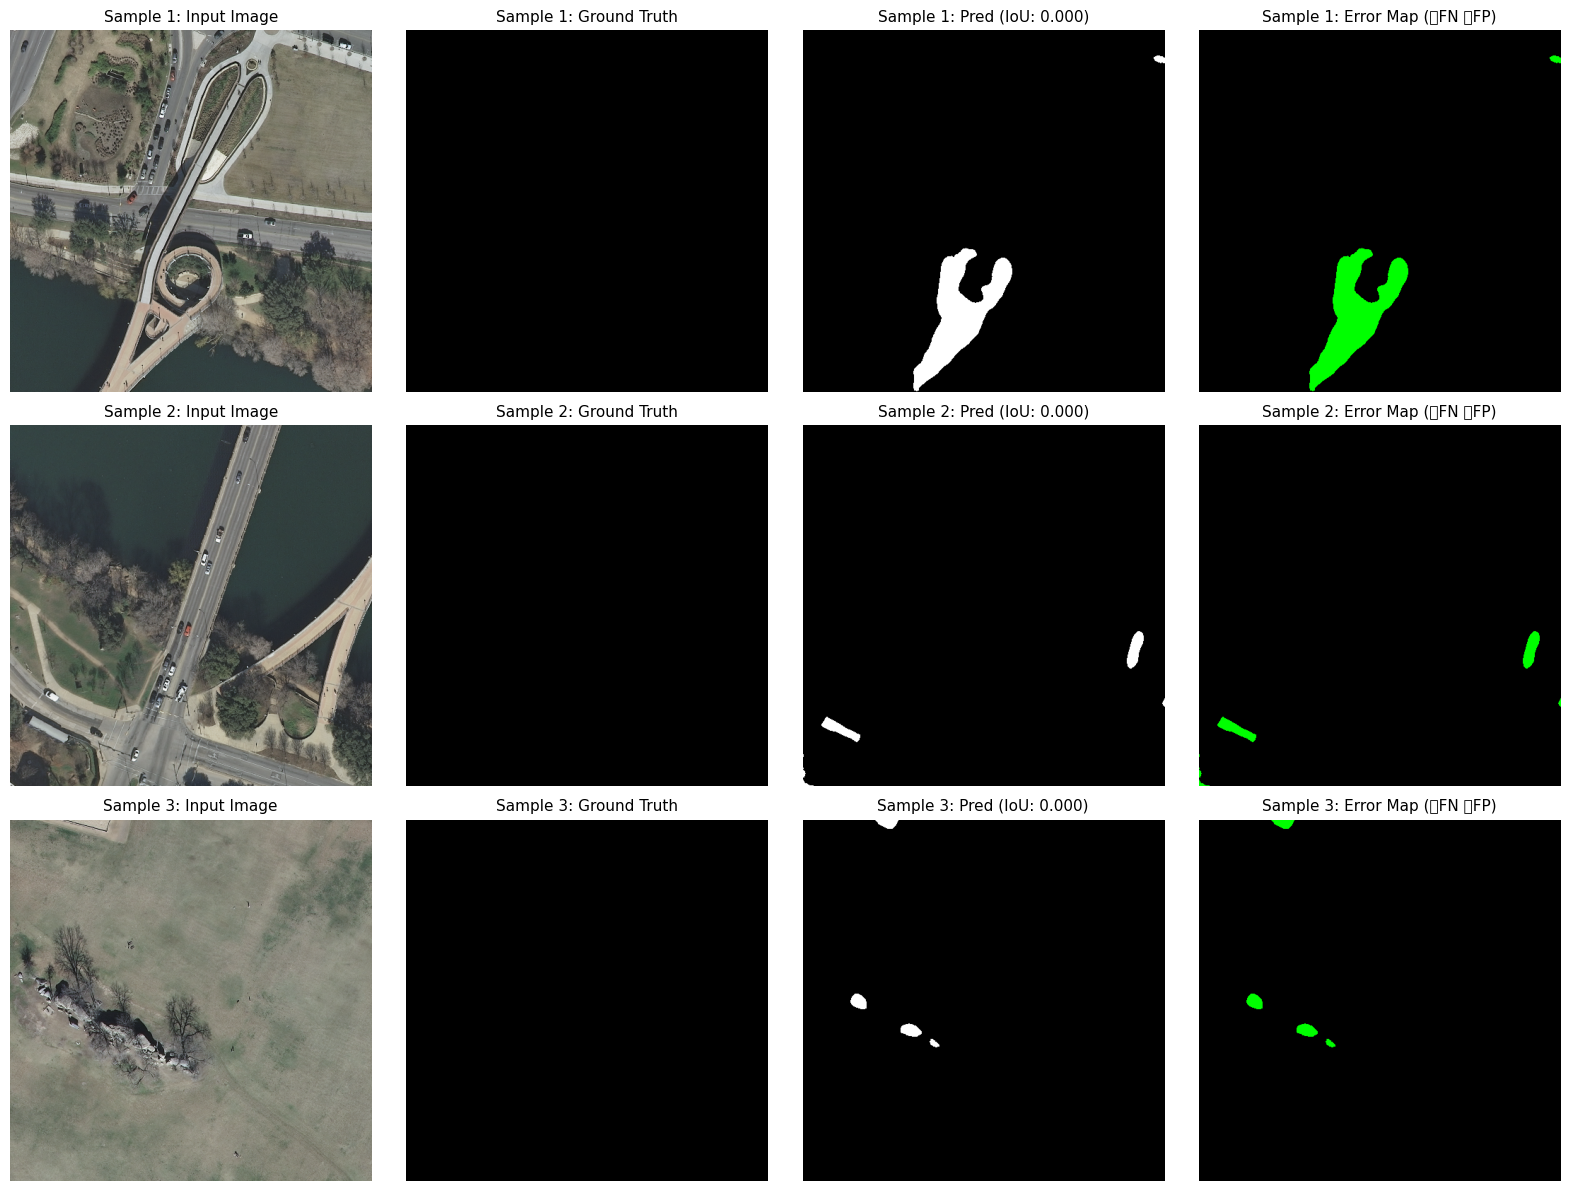

🎉 恭喜！失败案例分析图已完美生成并保存！点击下方链接下载：


/kaggle/working/edge_guided_unet_failure_cases.png

In [16]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset, random_split

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
img_dir = '/kaggle/working/inria_patches/images'
lbl_dir = '/kaggle/working/inria_patches/gt'

# ==========================================
# 1. 自动全盘搜索 edge_guided_unet_best.pth 权重路径
# ==========================================
WEIGHT_PATH = None
for root, _, files in os.walk('/kaggle'):
    if 'edge_guided_unet_best.pth' in files:
        WEIGHT_PATH = os.path.join(root, 'edge_guided_unet_best.pth')
        break

if WEIGHT_PATH is None:
    raise FileNotFoundError("❌ 未能在 /kaggle 目录下找到 edge_guided_unet_best.pth，请确认已在右侧 Input 区域成功上传该文件！")

print(f"🎯 成功匹配到绝对权重路径: {WEIGHT_PATH}")

# ==========================================
# 2. 原汁原味的 Edge-Guided U-Net 结构定义
# ==========================================
class EdgeGuidedUNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        resnet = models.resnet18(weights=None)  # 评估阶段加载结构即可
        self.initial = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.maxpool = resnet.maxpool
        self.enc1 = resnet.layer1 # 1/4 scale
        self.enc2 = resnet.layer2 # 1/8 scale
        self.enc3 = resnet.layer3 # 1/16 scale
        self.enc4 = resnet.layer4 # 1/32 scale
        
        self.edge_conv = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.edge_head = nn.Conv2d(32, 1, kernel_size=1)
        
        self.up4 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec4 = self._decoder_block(512 + 256, 256)
        
        self.up3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec3 = self._decoder_block(256 + 128, 128)
        
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec2 = self._decoder_block(128 + 64 + 32, 64)
        
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec1 = self._decoder_block(64 + 64, 64)
        
        self.final_up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.classifier = nn.Conv2d(64, num_classes, kernel_size=1)

    def _decoder_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        input_shape = x.shape[2:]
        
        x0 = self.initial(x)
        x1 = self.maxpool(x0)
        e1 = self.enc1(x1) 
        e2 = self.enc2(e1) 
        e3 = self.enc3(e2) 
        e4 = self.enc4(e3) 
        
        edge_feat = self.edge_conv(e2) 
        edge_out = self.edge_head(edge_feat)
        
        d4 = self.dec4(torch.cat([self.up4(e4), e3], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e2], dim=1))
        
        edge_feat_up = F.interpolate(edge_feat, size=e1.shape[2:], mode='bilinear', align_corners=False)
        d2 = self.dec2(torch.cat([self.up2(d3), e1, edge_feat_up], dim=1))
        
        d1 = self.dec1(torch.cat([self.up1(d2), x0], dim=1))
        
        out = self.classifier(self.final_up(d1))
        
        out = F.interpolate(out, size=input_shape, mode='bilinear', align_corners=False)
        edge_out = F.interpolate(edge_out, size=input_shape, mode='bilinear', align_corners=False)
            
        return out, edge_out

# ==========================================
# 3. 严格对齐随机种子 (Seed=42) 加载验证集
# ==========================================
class InriaPatchDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_names = sorted(os.listdir(img_dir))

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        image = Image.open(os.path.join(self.img_dir, img_name)).convert('RGB')
        label = Image.open(os.path.join(self.lbl_dir, img_name)).convert('L')
        label_np = (np.array(label) > 127).astype(np.int64)
        return torchvision.transforms.ToTensor()(image), torch.tensor(label_np, dtype=torch.long), img_name

full_dataset = InriaPatchDataset(img_dir, lbl_dir)
train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size
_, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)
val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False)

# ==========================================
# 4. 加载模型与权重
# ==========================================
print("🔄 正在加载 Edge-Guided U-Net 模型与权重...")
model = EdgeGuidedUNet(num_classes=2).to(DEVICE)
model.load_state_dict(torch.load(WEIGHT_PATH, map_location=DEVICE))
model.eval()

# ==========================================
# 5. 全局检索表现最差 (IoU 最低) 的 3 个案例
# ==========================================
print("🔍 正在扫描验证集寻找典型失败案例 (Failure Cases)...")
sample_errors = []

with torch.no_grad():
    for images, labels, img_names in tqdm(val_loader, desc="Searching Worst Cases"):
        images_dev = images.to(DEVICE)
        out_seg, _ = model(images_dev)
        preds = torch.argmax(out_seg, dim=1).cpu().numpy()[0]
        gt = labels.numpy()[0]
        
        intersection = np.logical_and(preds, gt).sum()
        union = np.logical_or(preds, gt).sum()
        iou = (intersection + 1e-6) / (union + 1e-6)
        
        sample_errors.append({
            'image': images[0].permute(1, 2, 0).numpy(),
            'gt': gt,
            'pred': preds,
            'iou': iou,
            'name': img_names[0]
        })

sample_errors.sort(key=lambda x: x['iou'])
worst_samples = sample_errors[:3]

# ==========================================
# 6. 绘制失败案例对比图与 Error Map
# ==========================================
print("🎨 正在绘制失败案例分析图...")
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i, item in enumerate(worst_samples):
    img = np.clip(item['image'], 0, 1)
    gt = item['gt']
    pred = item['pred']
    iou_val = item['iou']
    
    # 构建 Error Map (🔴红色: 漏检 FN, 🟢绿色: 误检 FP)
    error_map = np.zeros((*gt.shape, 3), dtype=np.float32)
    error_map[(gt == 1) & (pred == 0)] = [1.0, 0.0, 0.0]  
    error_map[(gt == 0) & (pred == 1)] = [0.0, 1.0, 0.0]  
    
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Sample {i+1}: Input Image", fontsize=11)
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(gt, cmap='gray')
    axes[i, 1].set_title(f"Sample {i+1}: Ground Truth", fontsize=11)
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(pred, cmap='gray')
    axes[i, 2].set_title(f"Sample {i+1}: Pred (IoU: {iou_val:.3f})", fontsize=11)
    axes[i, 2].axis('off')
    
    axes[i, 3].imshow(error_map)
    axes[i, 3].set_title(f"Sample {i+1}: Error Map (🔴FN 🟢FP)", fontsize=11)
    axes[i, 3].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/edge_guided_unet_failure_cases.png', dpi=300)
plt.show()

from IPython.display import FileLink
print("🎉 恭喜！失败案例分析图已完美生成并保存！点击下方链接下载：")
display(FileLink('/kaggle/working/edge_guided_unet_failure_cases.png'))

找到模型文件啦！真实路径是：
/kaggle/input/datasets/xiaomaoperson/my-edge-unet-model/edge_guided_unet_best.pth
